Requirements: Trying GPU Tesla T4 GPU 14.6BG

This code is tested in the following environment:

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

PyTorch: 2.14.1+cu130

GPU: Tesla T4

GPU memory (GiB): 14.6

In [2]:
!pip -q install git+https://github.com/facebookresearch/sam2.git
!pip -q install pillow

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [1]:
# Define the global variables

SEED = 42
# Choose the diverse total number of images to sample from all classes
N_IMAGES = 150
# Choose only small images
MAX_FILE_BYTES = 1_500_000

# Use PlantDoc dataset
REPO = "pratikkayal/PlantDoc-Dataset"
BRANCH = "master"
TREE_URL = f"https://api.github.com/repos/{REPO}/git/trees/{BRANCH}?recursive=1"


In [12]:
import json
import sys
import torch
import random
import requests
from collections import defaultdict
from urllib.parse import quote
from google.colab import drive
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Imports for Segment Anything 2
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

In [5]:
# Check if GPU is available
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Enable a GPU runtime in Colab.")

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory (GiB):",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1)
)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA L4
GPU memory (GiB): 22.0


In [6]:
# Define folders for writing the image, mask and annotation
drive.mount("/content/drive")
PROJECT_DIR = Path("/content/")
IMAGE_DIR = PROJECT_DIR / "images"
MASK_DIR = PROJECT_DIR / "masks"
ANNOTATION_DIR = PROJECT_DIR / "annotations"

for path in (IMAGE_DIR, MASK_DIR, ANNOTATION_DIR):
    path.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Mounted at /content/drive
Project directory: /content


In [7]:
#
response = requests.get(TREE_URL, timeout=60)
response.raise_for_status()
tree = response.json()["tree"]

extensions = {".jpg", ".jpeg", ".png"}
image_records = []

for item in tree:
    parts = item["path"].split("/")
    if (
        item["type"] == "blob"
        and len(parts) >= 3
        and parts[0] in {"train", "test"}
        and Path(item["path"]).suffix.lower() in extensions
        and item.get("size", 0) <= MAX_FILE_BYTES
    ):
        image_records.append({
            "path": item["path"],
            "class_name": parts[1],
            "size": item.get("size", 0),
        })

print("Eligible images:", len(image_records))
print("Classes:", len({item["class_name"] for item in image_records}))


Eligible images: 2397
Classes: 28


In [8]:
random.seed(SEED)
# Sample approximately evenly across available classes.
by_class = defaultdict(list)
for record in image_records:
    by_class[record["class_name"]].append(record)

class_names = sorted(by_class)
for values in by_class.values():
    random.shuffle(values)

selected = []
while len(selected) < min(N_IMAGES, len(image_records)):
    added = False
    for class_name in class_names:
        if by_class[class_name] and len(selected) < N_IMAGES:
            selected.append(by_class[class_name].pop())
            added = True
    if not added:
        break

print("Selected:", len(selected))

Selected: 150


In [9]:
downloaded = []

for index, record in enumerate(selected):
    filename = f"{index:04d}_{Path(record['path']).name}"
    destination = IMAGE_DIR / filename

    if destination.exists() and destination.stat().st_size > 0:
        downloaded.append(destination)
        continue

    url = (
        f"https://raw.githubusercontent.com/{REPO}/{BRANCH}/"
        f"{quote(record['path'], safe='/')}"
    )

    try:
        result = requests.get(url, timeout=45)
        result.raise_for_status()
        destination.write_bytes(result.content)
        downloaded.append(destination)
    except Exception as error:
        print("Skipped", record["path"], ":", str(error)[:150])

print("Downloaded or reused:", len(downloaded))

Downloaded or reused: 150


In [10]:
CHECKPOINT_DIR = Path("/content/checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)
CHECKPOINT = CHECKPOINT_DIR / "sam2.1_hiera_large.pt"
CHECKPOINT_URL = (
    "https://dl.fbaipublicfiles.com/segment_anything_2/"
    "092824/sam2.1_hiera_large.pt"
)

if not CHECKPOINT.exists():
    with requests.get(
        CHECKPOINT_URL, stream=True, timeout=180
    ) as response:
        response.raise_for_status()
        with CHECKPOINT.open("wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)

MODEL_CONFIG = "configs/sam2.1/sam2.1_hiera_l.yaml"
sam_model = build_sam2(MODEL_CONFIG, str(CHECKPOINT), device="cuda")
predictor = SAM2ImagePredictor(sam_model)

print("SAM 2.1 Hiera-Large loaded.")

SAM 2.1 Hiera-Large loaded.


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [14]:
mask_generator = SAM2AutomaticMaskGenerator(
    model=sam_model,
    points_per_side=32,
    pred_iou_thresh=0.7,
    stability_score_thresh=0.90,
    crop_n_layers=1,
    min_mask_region_area=100,
)

In [16]:
def generate_mask(image_path):

    # Ensure the image array is writable.
    image = np.array(
        Image.open(image_path).convert("RGB"),
        copy=True
    )

    height, width = image.shape[:2]
    combined_mask = np.zeros((height, width), dtype=np.uint8)

    candidates = mask_generator.generate(image)
    selected = []

    for candidate in candidates:

        mask = candidate["segmentation"]
        area_fraction = candidate["area"] / (height * width)

        # Basic filtering; thresholds need validation.
        if area_fraction < 0.005:
            continue

        if candidate["predicted_iou"] < 0.80:
            continue

        if candidate["stability_score"] < 0.90:
            continue

        selected.append(candidate)

        # Combine selected candidate masks.
        combined_mask |= mask.astype(np.uint8)

    metadata = {
        "image": Path(image_path).name,
        "candidate_count": len(candidates),
        "selected_count": len(selected),
        "mask_area_fraction": float(combined_mask.mean()),
    }

    return image, combined_mask, metadata

In [17]:
MAX_ANNOTATIONS = 150
MIN_MASK_FRACTION = 0.01
MAX_MASK_FRACTION = 0.98

annotation_records = []
failed_images = []

for index, image_path in enumerate(downloaded[:MAX_ANNOTATIONS], start=1):
    try:
        image, mask, metadata = generate_mask(image_path)
        area = metadata["mask_area_fraction"]

        if MIN_MASK_FRACTION <= area <= MAX_MASK_FRACTION:
            mask_path = MASK_DIR / f"{image_path.stem}.png"
            Image.fromarray(mask * 255).save(mask_path)
            metadata["mask_path"] = str(mask_path)
            annotation_records.append(metadata)
        else:
            failed_images.append(image_path.name)

    except Exception as error:
        failed_images.append(image_path.name)
        print("Failed:", image_path.name, ":", str(error)[:150])

    if index % 10 == 0:
        print(f"{index}/{min(len(downloaded), MAX_ANNOTATIONS)} processed")

print("Saved masks:", len(annotation_records))
print("Skipped or failed:", len(failed_images))

10/150 processed
20/150 processed
30/150 processed
40/150 processed
50/150 processed
60/150 processed
70/150 processed
80/150 processed
90/150 processed
100/150 processed
110/150 processed
120/150 processed
130/150 processed
140/150 processed
150/150 processed
Saved masks: 142
Skipped or failed: 8


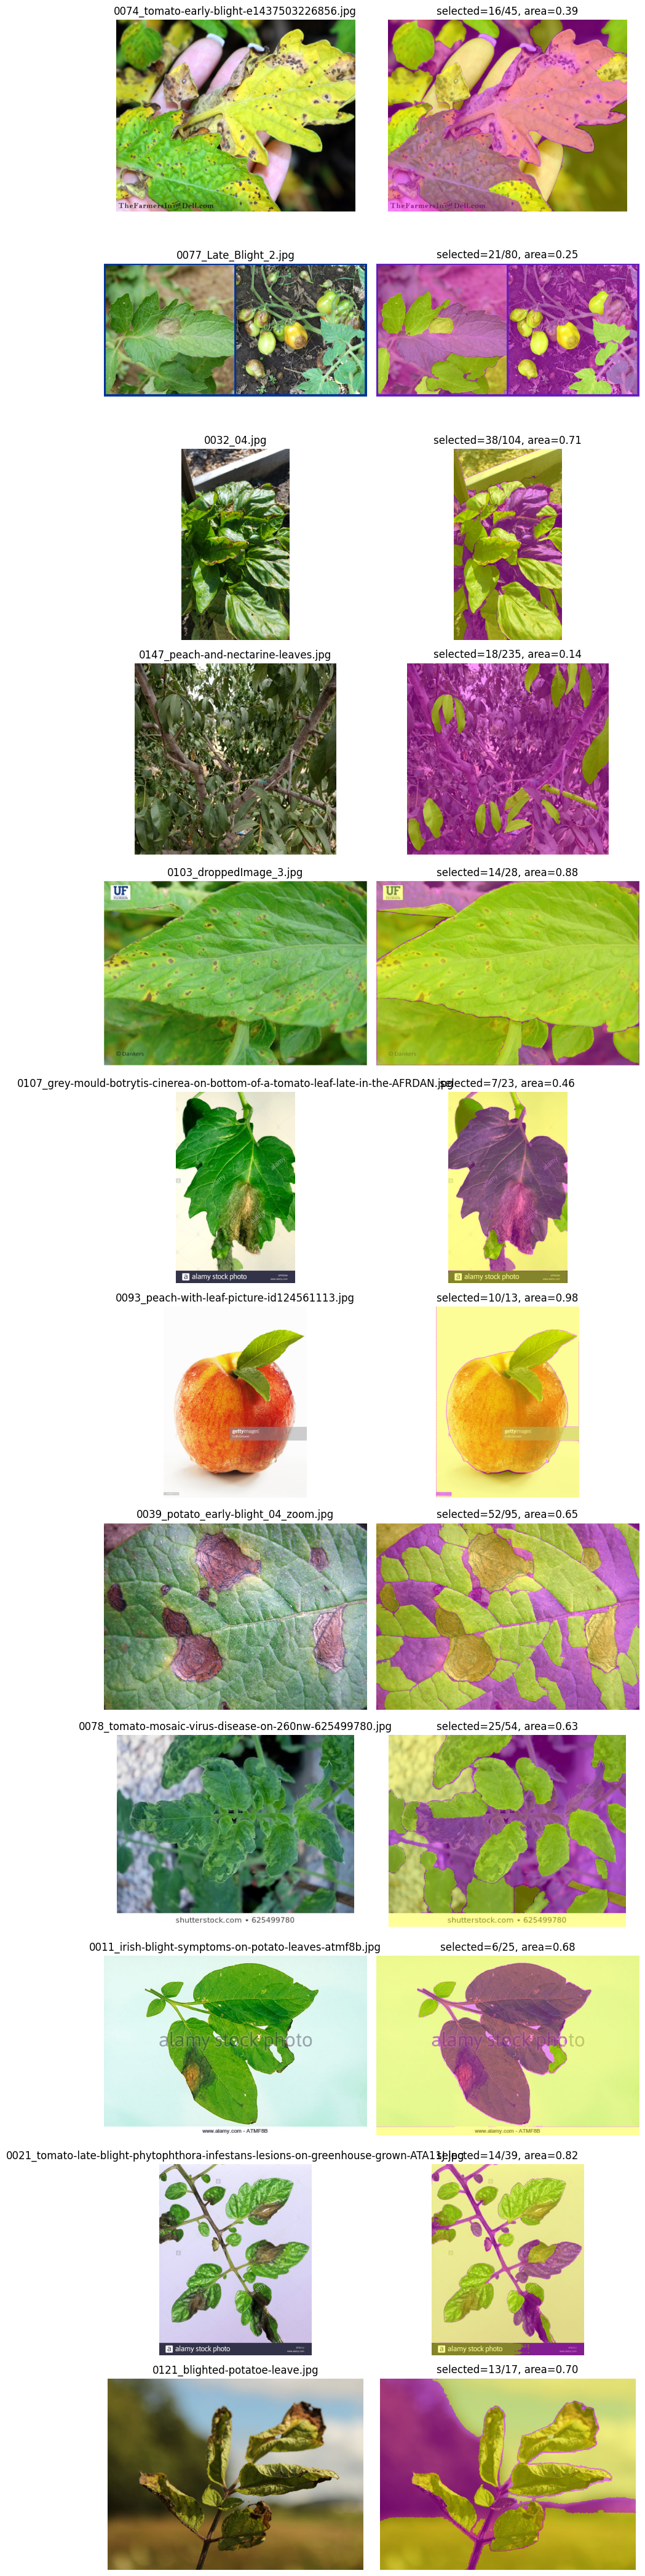

In [19]:
def show_mask_review(records, n=12):
    if not records:
        raise RuntimeError("No masks were generated.")

    sample = random.sample(records, min(n, len(records)))
    fig, axes = plt.subplots(len(sample), 2, figsize=(9, 3.5 * len(sample)))

    if len(sample) == 1:
        axes = np.asarray([axes])

    for row, record in enumerate(sample):
        image = np.asarray(
            Image.open(IMAGE_DIR / record["image"]).convert("RGB")
        )
        mask = (
            np.asarray(Image.open(record["mask_path"]).convert("L")) > 127
        )

        axes[row, 0].imshow(image)
        axes[row, 0].set_title(record["image"])
        axes[row, 1].imshow(image)
        axes[row, 1].imshow(mask, alpha=0.4, cmap="spring")
        axes[row, 1].set_title(
            f"selected={record.get('selected_count', 0)}/{record.get('candidate_count', 0)}, "
            f"area={record['mask_area_fraction']:.2f}"
        )

        for axis in axes[row]:
            axis.axis("off")

    plt.tight_layout()
    plt.show()


show_mask_review(annotation_records)

In [20]:
manifest_path = ANNOTATION_DIR / "manifest.json"

manifest = {
    "annotator": "SAM 2.1 Hiera-Large",
    "annotation_method": "Automatic Mask Generation (AMG)",
    "prompt": None,
    "filtering": {
        "min_area_fraction": 0.005,
        "min_predicted_iou": 0.80,
        "min_stability_score": 0.90,
    },
    "mask_type": "combined_binary_mask",
    "seed": SEED,
    "annotations": annotation_records,
    "failed_images": failed_images,
}

manifest_path.write_text(json.dumps(manifest, indent=2))

print("Manifest:", manifest_path)
print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)

del mask_generator, sam_model
torch.cuda.empty_cache()

Manifest: /content/annotations/manifest.json
Image directory: /content/images
Mask directory: /content/masks


In [24]:
import shutil
from pathlib import Path

dest_root = Path("/content/drive/MyDrive/Colab Notebooks/GitHub/Proximal Imaging/SAM-UNet")
dest_images = dest_root / "images"
dest_masks = dest_root / "masks"

# Safely remove existing destination directories if they exist to force write
for dest_path in (dest_images, dest_masks):
    if dest_path.exists():
        print(f"Removing existing destination directory: {dest_path}")
        shutil.rmtree(dest_path)

# Move the newly generated images and masks
print("Moving images...")
shutil.move("/content/images", str(dest_images))

print("Moving masks...")
shutil.move("/content/masks", str(dest_masks))

print("Move completed successfully!")

Removing existing destination directory: /content/drive/MyDrive/Colab Notebooks/GitHub/Proximal Imaging/SAM-UNet/images
Removing existing destination directory: /content/drive/MyDrive/Colab Notebooks/GitHub/Proximal Imaging/SAM-UNet/masks
Moving images...
Moving masks...
Move completed successfully!


In [ ]:
!mv "/content/annotations/" "/content/drive/MyDrive/Colab Notebooks/GitHub/Proximal Imaging/SAM-UNet/"

In [25]:
import shutil
from pathlib import Path

dest_root = Path("/content/drive/MyDrive/Colab Notebooks/GitHub/Proximal Imaging/SAM-UNet")
dest_annotations = dest_root / "annotations"

# Safely remove existing annotations directory if it exists to force write
if dest_annotations.exists():
    print(f"Removing existing destination directory: {dest_annotations}")
    shutil.rmtree(dest_annotations)

# Move the newly generated annotations directory
print("Moving annotations...")
shutil.move("/content/annotations", str(dest_annotations))

print("Annotations move completed successfully!")

Removing existing destination directory: /content/drive/MyDrive/Colab Notebooks/GitHub/Proximal Imaging/SAM-UNet/annotations
Moving annotations...
Annotations move completed successfully!
